<a href="https://colab.research.google.com/github/Zeldachild/remote_host/blob/main/22_8_Final_Stroke_Prediction_Valentine_Submission.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#import the required package
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler, RobustScaler
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix, make_scorer

#from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn import metrics


# Libraries to Hyperparameter Tuning
#from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, loguniform, uniform


# To filter Warnings
import warnings

%matplotlib inline
sns.set()

In [ ]:
dataframe = pd.read_csv("Transformed_Stroke_Dataset_Updated_v2.csv")

In [ ]:
#checking the data head
dataframe.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,...,lifestyle_type,blood_pressure_(mmHg),cholesterol_level_(mg/dl),alcohol_status,physical_activity_status,family_stroke_history_status,imaging_modality,lesion_status,lesion_size_(cm),scan_quality
0,1,Female,74,0,1,1,Private,Urban,118.690215,30.156540,...,"Non-smoker, non-drinker",168/86,260,Yes,Low,Yes,CT,Left Hemisphere,4.802246,Poor
1,2,Male,57,1,0,1,Government Job,Rural,193.592860,27.507778,...,"Smoker, regular alcohol consumption",158/104,159,No,Moderate,No,MRI,Cerebellum,0.558943,Poor
2,3,Male,57,1,1,1,Never worked,Rural,165.159212,31.050719,...,"Smoker, regular alcohol consumption",151/83,148,Yes,Low,No,CT,Multiple,1.946336,Poor
3,4,Female,67,1,0,1,Private,Urban,147.825603,32.905512,...,"Non-smoker, non-drinker",143/115,254,No,Low,No,CT,Cerebellum,3.910397,Moderate
4,5,Male,62,1,1,1,Never worked,Rural,90.282423,29.790438,...,"Smoker, regular alcohol consumption",142/85,250,Yes,Moderate,Yes,CT,Multiple,1.126870,Moderate


In [ ]:
dataframe = pd.read_csv("Transformed_Stroke_Dataset_Updated_2.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'Transformed_Stroke_Dataset_Updated_2.csv'

In [ ]:
#checking the data head
df = dataframe.head()

In [ ]:
# checking the dimension
dataframe.shape

(1000, 25)

In [ ]:
def detect_noise_zscore(dataframe, threshold=3):
    z_scores = np.abs(stats.zscore(dataframe.select_dtypes(include=[np.number])))
    noise = (z_scores > threshold).sum(axis=1)
    noise_data = dataframe[noise > 0]
    return noise_data

In [ ]:
def detect_noise_iqr(dataframe):
    Q1 = dataframe.quantile(0.25)
    Q3 = dataframe.quantile(0.75)
    IQR = Q3 - Q1
    noise = ((dataframe < (Q1 - 1.5 * IQR)) | (dataframe > (Q3 + 1.5 * IQR))).sum(axis=1)
    noise_data = dataframe[noise > 0]
    return noise_data

In [ ]:
noise_iqr = detect_noise_iqr(df)
print("Noise detected using IQR:")
print(noise_iqr)

Noise detected using IQR:
   id  gender  age  hypertension  heart_disease  ever_married       work_type  \
0   1  Female   74             0              1             1         Private   
1   2    Male   57             1              0             1  Government Job   

  Residence_type  avg_glucose_level        bmi  ...  \
0          Urban         118.690215  30.156540  ...   
1          Rural         193.592860  27.507778  ...   

                        lifestyle_type  blood_pressure_(mmHg)  \
0              Non-smoker, non-drinker                 168/86   
1  Smoker, regular alcohol consumption                158/104   

  cholesterol_level_(mg/dl) alcohol_status physical_activity_status  \
0                       260            Yes                      Low   
1                       159             No                 Moderate   

  family_stroke_history_status imaging_modality    lesion_status  \
0                          Yes               CT  Left Hemisphere   
1                 

C:\Users\DELL\AppData\Local\Temp\ipykernel_18292\34821470.py:2: FutureWarning: The default value of numeric_only in DataFrame.quantile is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  Q1 = dataframe.quantile(0.25)
C:\Users\DELL\AppData\Local\Temp\ipykernel_18292\34821470.py:3: FutureWarning: The default value of numeric_only in DataFrame.quantile is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  Q3 = dataframe.quantile(0.75)
C:\Users\DELL\AppData\Local\Temp\ipykernel_18292\34821470.py:5: FutureWarning: Automatic reindexing on DataFrame vs Series comparisons is deprecated and will raise ValueError in a future version. Do `left, right = left.align(right, axis=1, copy=False)` before e.g. `left == right`
  noise = ((dataframe < (Q1 - 1.5 * IQR)) | (dataframe > (Q3 + 1.5 * IQR))).sum(axis=

In [ ]:
def cap_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

In [ ]:
return series.apply(lambda x: lower_bound if x < lower_bound else upper_bound if x > upper_bound else x)

SyntaxError: 'return' outside function (281232984.py, line 1)

In [ ]:
for col in df.select_dtypes(include=['float64', 'int64']).columns:
    df[col] = cap_outliers(df[col])

C:\Users\DELL\AppData\Local\Temp\ipykernel_18292\3184903942.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col] = cap_outliers(df[col])
C:\Users\DELL\AppData\Local\Temp\ipykernel_18292\3184903942.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col] = cap_outliers(df[col])
C:\Users\DELL\AppData\Local\Temp\ipykernel_18292\3184903942.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the c

In [ ]:
# Check the results
print(df.describe())

         id gender  age hypertension heart_disease ever_married work_type  \
count     0      5    0            0             0            0         5   
unique    0      2    0            0             0            0         3   
top     NaN   Male  NaN          NaN           NaN          NaN   Private   
freq    NaN      3  NaN          NaN           NaN          NaN         2   

       Residence_type avg_glucose_level  bmi  ...  \
count               5                 0    0  ...   
unique              2                 0    0  ...   
top             Rural               NaN  NaN  ...   
freq                3               NaN  NaN  ...   

                             lifestyle_type blood_pressure_(mmHg)  \
count                                     5                     5   
unique                                    2                     5   
top     Smoker, regular alcohol consumption                168/86   
freq                                      3                     1   

  

In [ ]:
dataframe.describe().round(2)

,id,age,hypertension,heart_disease,ever_married,avg_glucose_level,bmi,smoking_status,stroke,cholesterol_level_(mg/dl),lesion_size_(cm)
count,1000.00,1000.00,1000.00,1000.00,1000.0,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,500.50,61.29,0.58,0.56,1.0,133.73,27.68,0.56,0.48,222.82,2.86
std,288.82,10.68,0.49,0.50,0.0,37.98,4.23,0.50,0.50,46.28,1.40
min,1.00,40.00,0.00,0.00,1.0,70.60,18.09,0.00,0.00,140.00,0.00
25%,250.75,52.00,0.00,0.00,1.0,100.68,24.57,0.00,0.00,181.00,1.81
50%,500.50,61.50,1.00,1.00,1.0,134.58,27.80,1.00,0.00,223.00,2.78
75%,750.25,70.00,1.00,1.00,1.0,166.76,31.05,1.00,1.00,264.00,3.93
max,1000.00,84.00,1.00,1.00,1.0,199.96,36.44,1.00,1.00,305.00,5.92


In [ ]:
dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 25 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   id                            1000 non-null   int64  
 1   gender                        1000 non-null   object 
 2   age                           1000 non-null   int64  
 3   hypertension                  1000 non-null   int64  
 4   heart_disease                 1000 non-null   int64  
 5   ever_married                  1000 non-null   int64  
 6   work_type                     1000 non-null   object 
 7   Residence_type                1000 non-null   object 
 8   avg_glucose_level             1000 non-null   float64
 9   bmi                           1000 non-null   float64
 10  smoking_status                1000 non-null   int64  
 11  stroke                        1000 non-null   int64  
 12  Ethnicity                     1000 non-null   object 
 13  medi

In [ ]:
# checking the number of duplicated variable
dataframe.duplicated().sum()

0

In [ ]:
# checking the number of null value in each features/column
dataframe.isnull().sum()

id                              0
gender                          0
age                             0
hypertension                    0
heart_disease                   0
ever_married                    0
work_type                       0
Residence_type                  0
avg_glucose_level               0
bmi                             0
smoking_status                  0
stroke                          0
Ethnicity                       0
medical_history                 0
medications                     0
lifestyle_type                  0
blood_pressure_(mmHg)           0
cholesterol_level_(mg/dl)       0
alcohol_status                  0
physical_activity_status        0
family_stroke_history_status    0
imaging_modality                0
lesion_status                   0
lesion_size_(cm)                0
scan_quality                    0
dtype: int64

In [ ]:
#checking the unique variable in each features
dataframe.nunique()

id                              1000
gender                             2
age                               45
hypertension                       2
heart_disease                      2
ever_married                       1
work_type                          4
Residence_type                     2
avg_glucose_level               1000
bmi                             1000
smoking_status                     2
stroke                             2
Ethnicity                          3
medical_history                    8
medications                        8
lifestyle_type                     5
blood_pressure_(mmHg)             98
cholesterol_level_(mg/dl)        163
alcohol_status                     2
physical_activity_status           3
family_stroke_history_status       2
imaging_modality                   2
lesion_status                      5
lesion_size_(cm)                 993
scan_quality                       4
dtype: int64

In [ ]:
def plot_columns(column_names, data=dataframe):
    """
    Function to plot the distribution of categorical variables in the DataFrame.

    Parameters:
    data : DataFrame to be analyzed.
    column_names (list): Names of the columns to plot.

    Returns: output/shows a sns count plot for each passed column/variable
    """
    for col in column_names:
        sns.countplot(x=data[col])
        plt.title('Distribution of ' + col)
        plt.show()

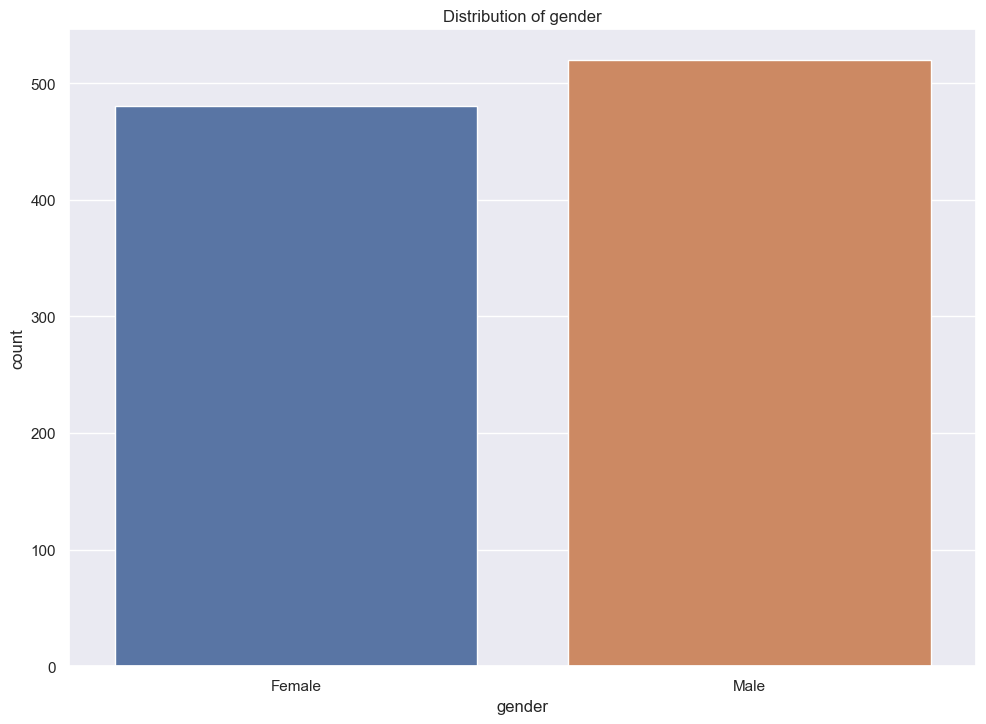

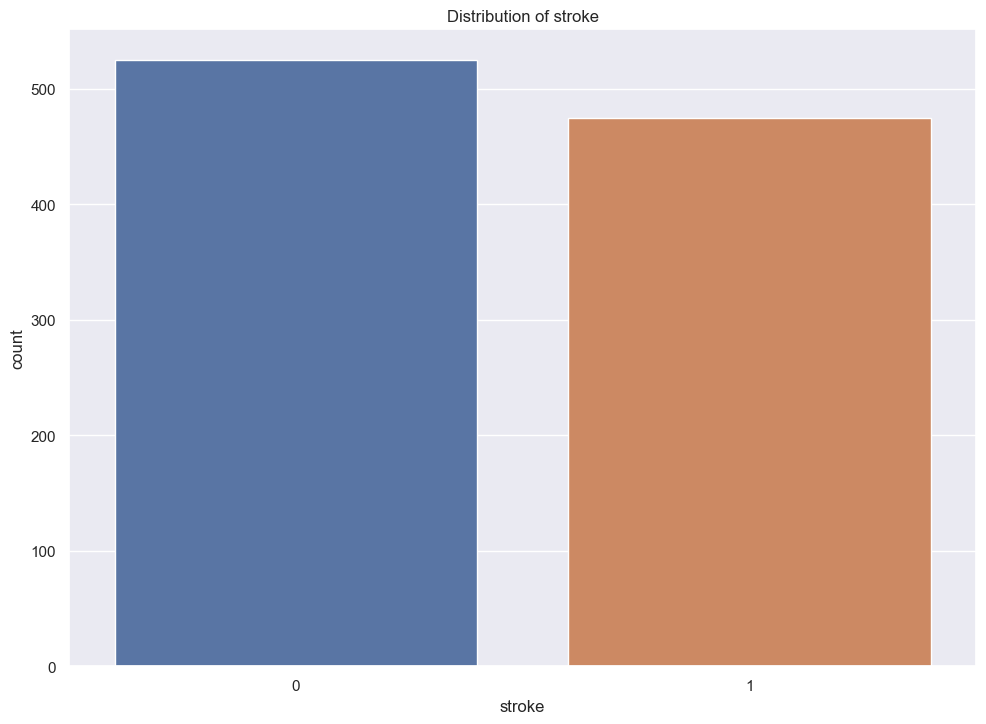

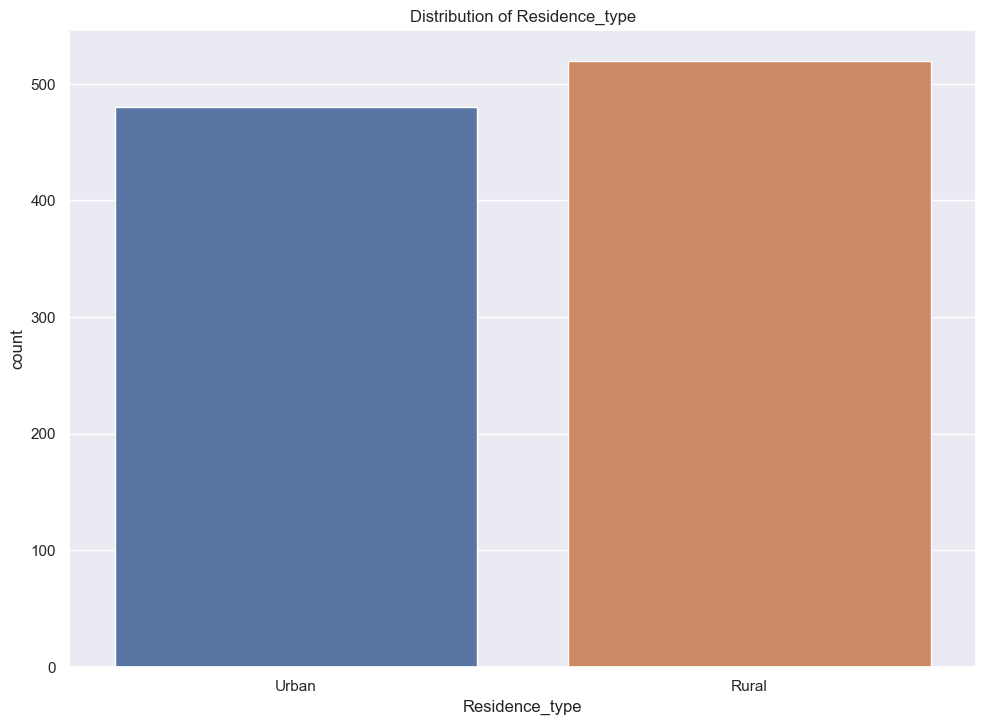

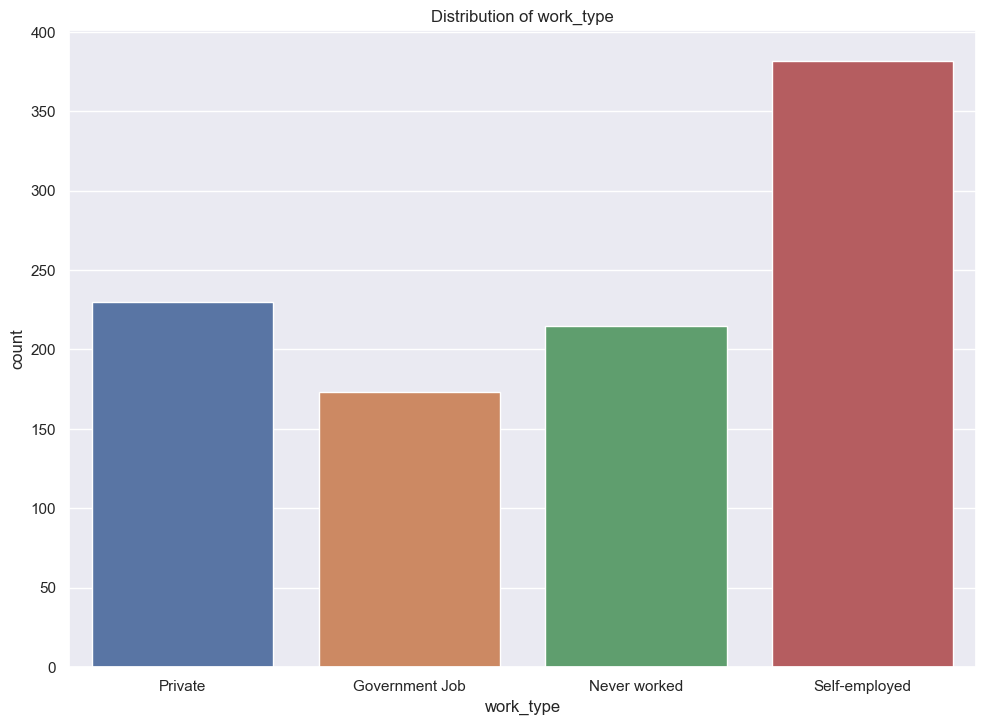

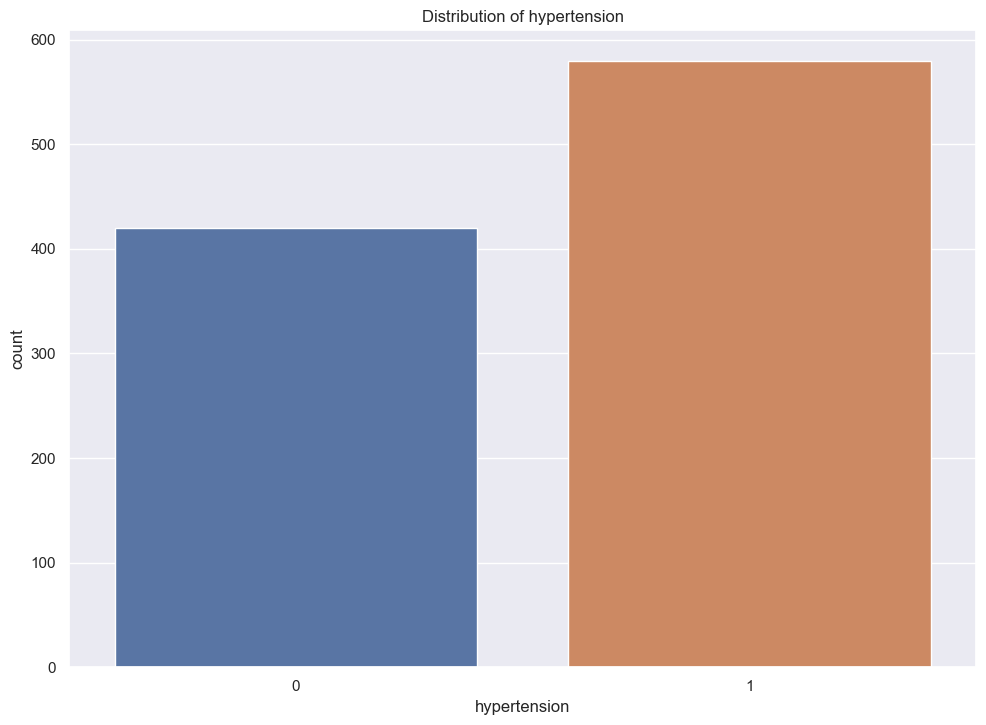

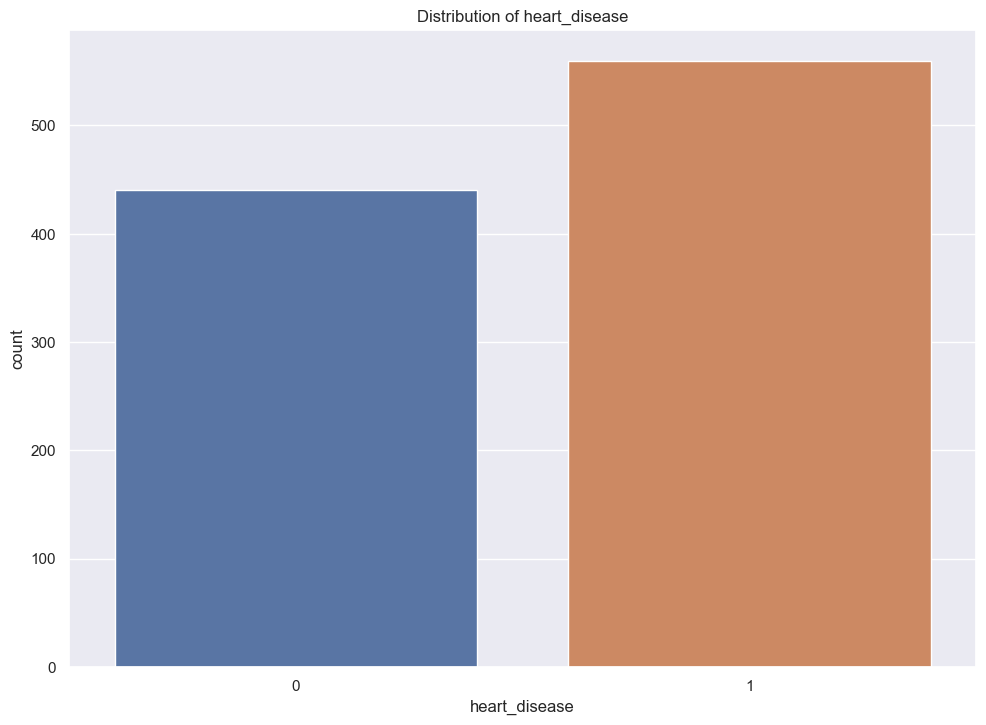

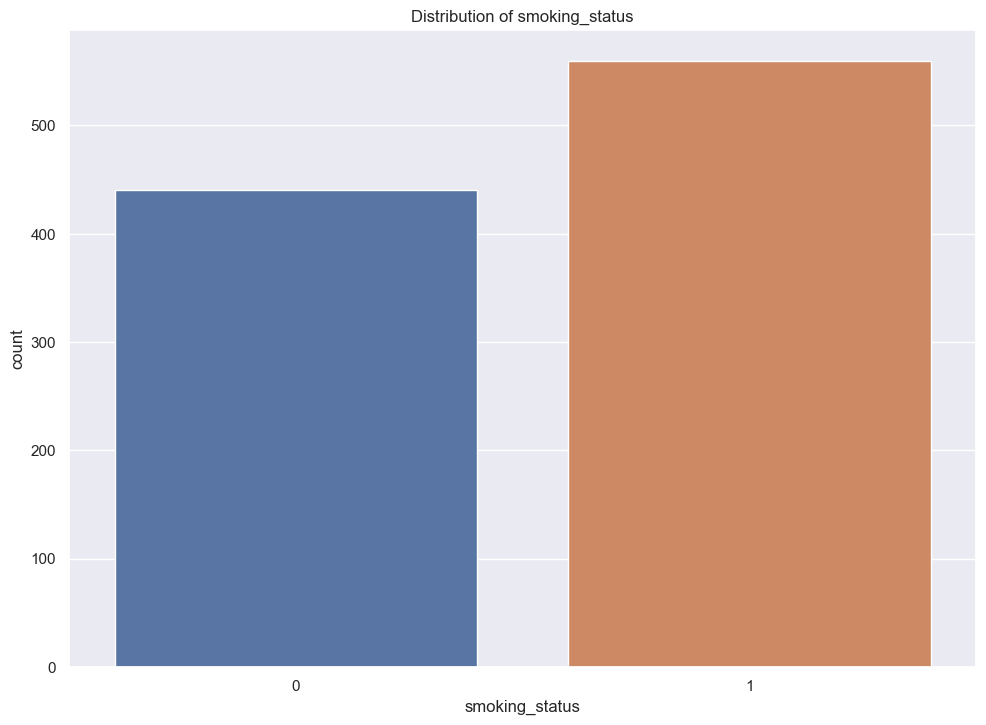

In [ ]:
# calling the count plot function with required argument(s) i.e. variables
plot_columns(['gender', 'stroke', 'Residence_type', 'work_type', 'hypertension', 'heart_disease', 'smoking_status'])

<Axes: xlabel='gender', ylabel='count'>

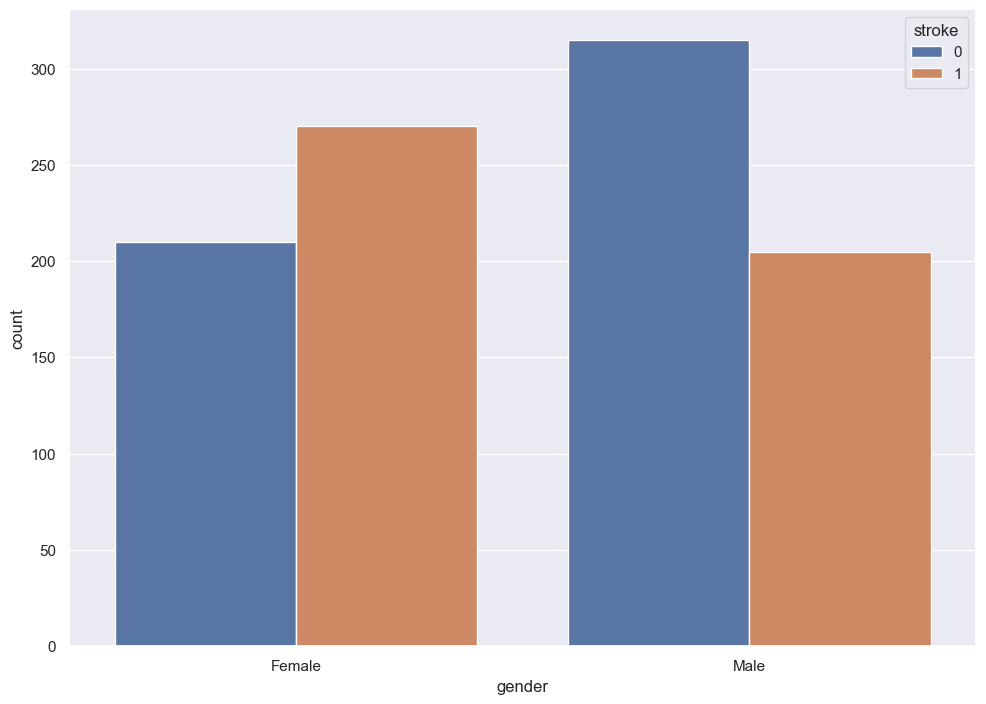

In [ ]:
#Bi-variate EDA with target variable and gender
sns.countplot(x="gender", hue="stroke", data=dataframe)

In [ ]:
def check_target_distribution_by_gender(data, target, gender_col='gender'):
    """
    Function to check the distribution of a binary target variable in a dataset by gender.

    Parameters:
    - data (pandas.DataFrame): Dataset to be analyzed.
    - target (str): Name of the binary target variable.
    - gender_col (str): Name of the column that contains gender information.

    Returns:
    - % of the gender in the traget variable
    - count of the responses in the target varaible
    - % of each response of the target varaible
    - A statement to confirm if the data is balance or not
    """

    # Calculate the percentage of samples with the target variable for each gender
    female_with_target = data[data[gender_col] == 'Female'][target].sum() / data[data[gender_col] == 'Female'][target].count() * 100
    male_with_target = data[data[gender_col] == 'Male'][target].sum() / data[data[gender_col] == 'Male'][target].count() * 100
    other_gender_with_target = data[data[gender_col] == 'Other'][target].sum() / data[data[gender_col] == 'Other'][target].count() * 100

    print("% of Female with {}: {:2.2f}%".format(target, female_with_target))
    print("% of Male with {}: {:2.2f}%".format(target, male_with_target))
    print("% of Other gender with {}: {:2.2f}%".format(target, other_gender_with_target))
    print('*' * 30)

    # Check the distribution of the target variable for the whole dataset
    target_counts = data[target].value_counts()
    print(target_counts)
    print('*' * 30)

    # Calculate the percentage of samples in each class
    percentage_target = target_counts[1] / len(data) * 100
    percentage_no_target = target_counts[0] / len(data) * 100
    print('Percentage of {} cases: {:.2f}%'.format(target, percentage_target))
    print('Percentage of non-{} cases: {:.2f}%'.format(target, percentage_no_target))
    print('*' * 30)

    if percentage_target == percentage_no_target:
        print('The dataset is balanced. Oversampling or undersampling may not be required.')
    else:
        print('The dataset is imbalanced. Oversampling or undersampling may be required.')




# calling the function with required argument(s)
check_target_distribution_by_gender(dataframe, 'stroke')

% of Female with stroke: 56.25%
% of Male with stroke: 39.42%
% of Other gender with stroke: nan%
******************************
0    525
1    475
Name: stroke, dtype: int64
******************************
Percentage of stroke cases: 47.50%
Percentage of non-stroke cases: 52.50%
******************************
The dataset is imbalanced. Oversampling or undersampling may be required.


C:\Users\DELL\AppData\Local\Temp\ipykernel_18292\4213267931.py:20: RuntimeWarning: invalid value encountered in scalar divide
  other_gender_with_target = data[data[gender_col] == 'Other'][target].sum() / data[data[gender_col] == 'Other'][target].count() * 100


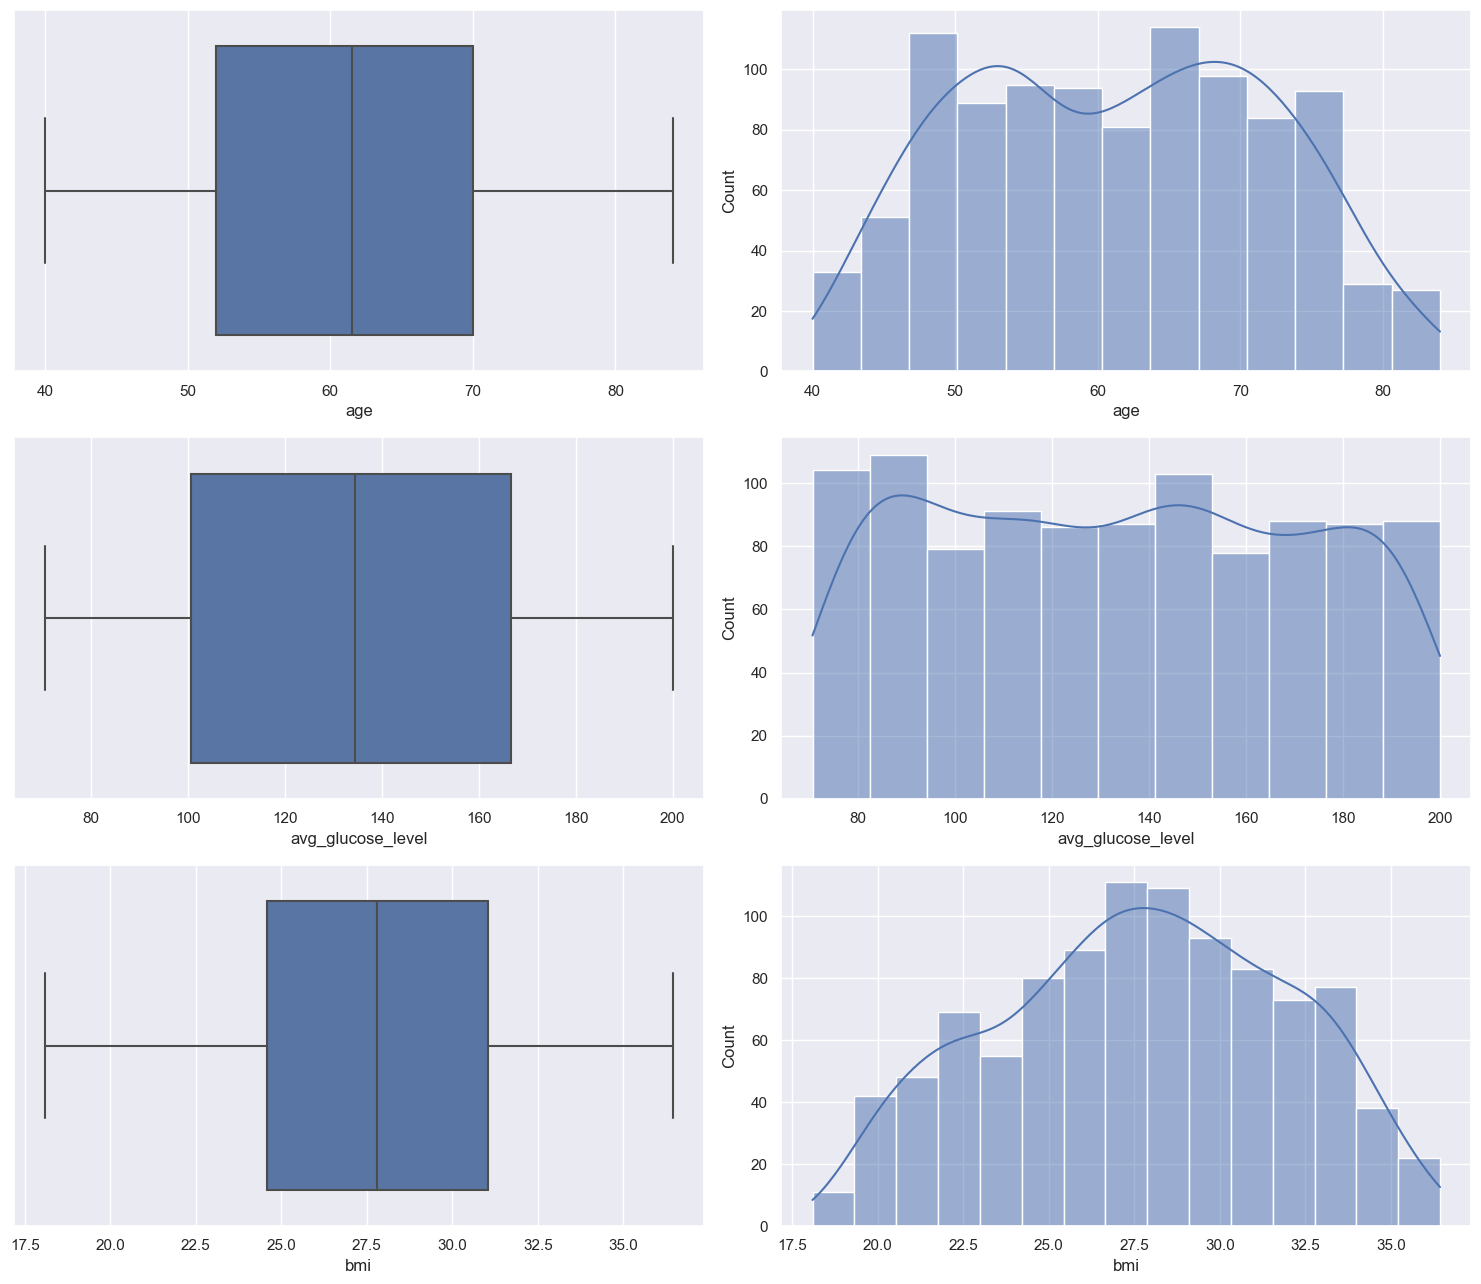

In [ ]:
#function to plot numeric variables

def plot_numeric_data(df, x_vars, figsize=(15, 13)):
    """
    Function plot box plot and histogram for the numeric variables.

    Parameters:
    - data (pandas.DataFrame): Dataset to be analyzed.

    - x_vars (list): list of numeric varibales.

    Returns:
    - A box plot and histogram for each variables passed

    """
    fig, ax = plt.subplots(len(x_vars), 2, figsize=figsize)
    for i, var in enumerate(x_vars):
        sns.boxplot(x=df[var], ax=ax[i, 0])
        sns.histplot(df[var], kde=True, ax=ax[i, 1])
    plt.tight_layout()


# calling the function with required argument(s)
plot_numeric_data(dataframe, ['age', 'avg_glucose_level', 'bmi'])

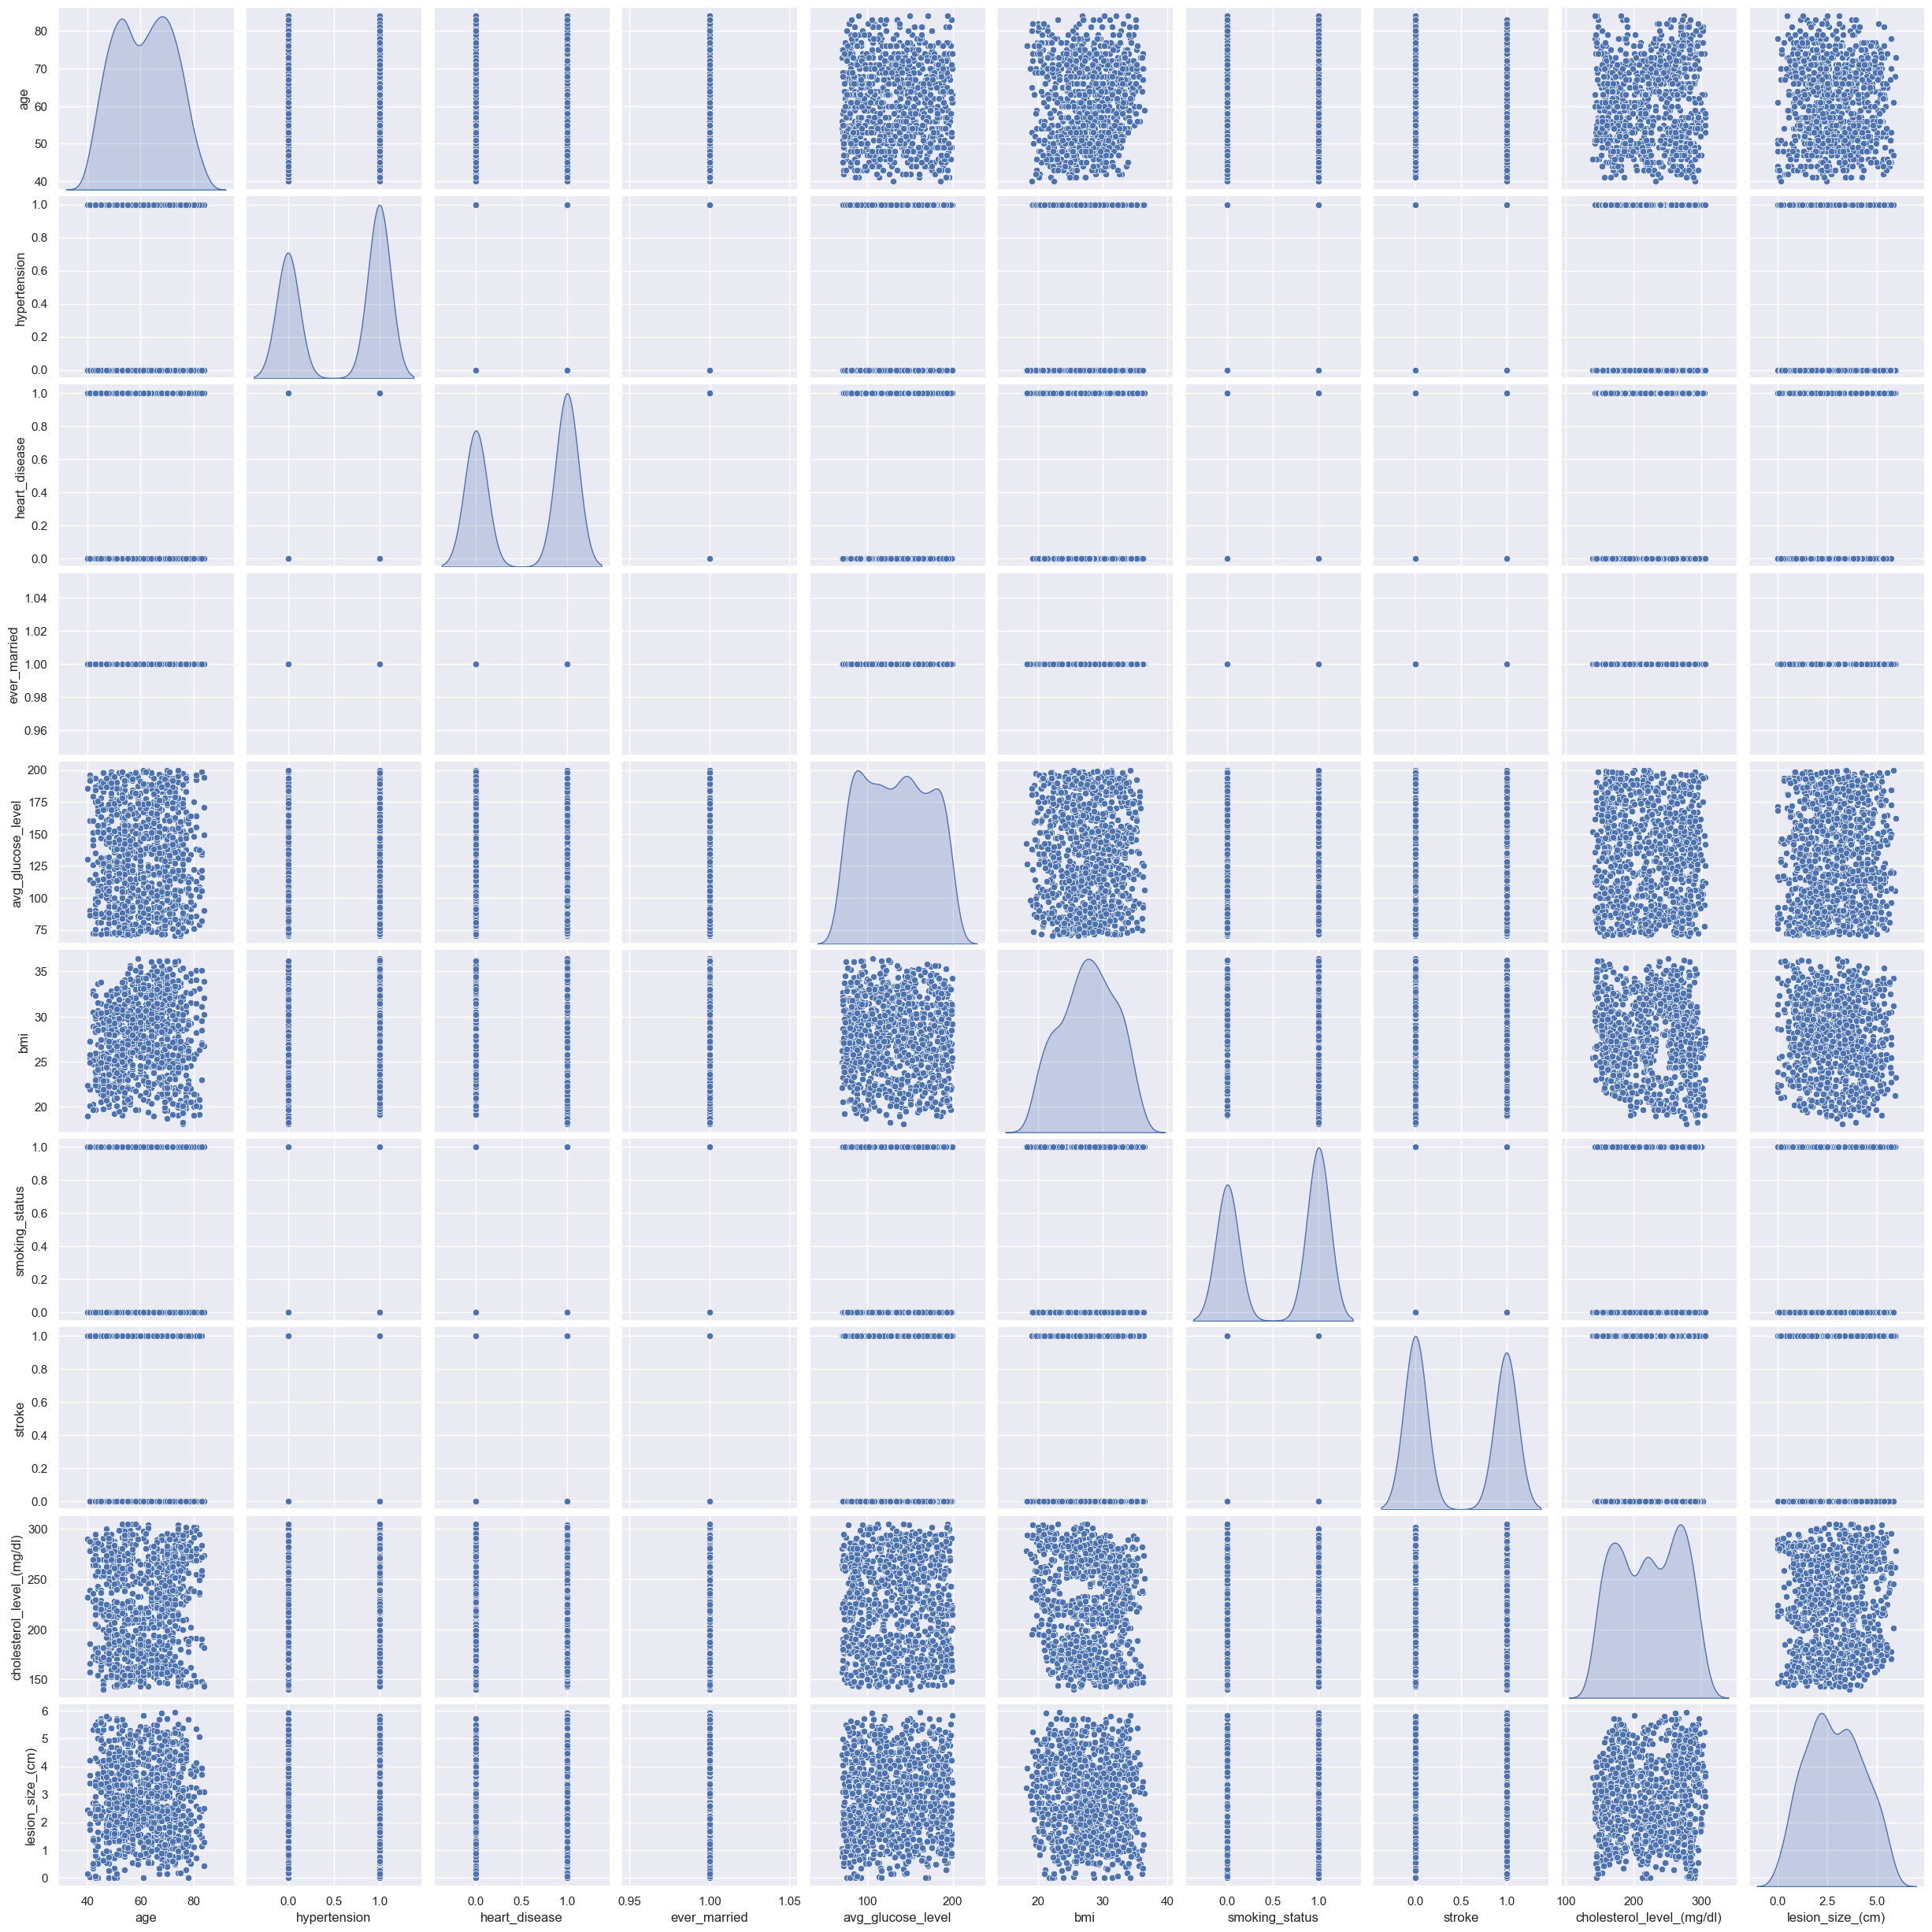

In [ ]:
#function to plot pairplot numeric variables
def create_pairplot(data):
    """
    Function to plot pairplot for all variables

    Parameters:
    - data (pandas.DataFrame): Dataset to be analyzed.

    Returns:
    - A pairplot that shows pairwise relationships between variables in the dataset

    """
    sns.set(rc={'figure.figsize':(11.7,8.27)})
    df_attr = data.iloc[:, 1:-1] # Select all columns except the id and target (the first and last)variable
    sns.pairplot(df_attr, diag_kind='kde')


# calling the function with required argument(s)
create_pairplot(dataframe)

C:\Users\DELL\AppData\Local\Temp\ipykernel_18292\4262876291.py:14: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  sns.heatmap(data.iloc[:, 1:].corr(), cmap=plt.cm.Reds, annot=True)


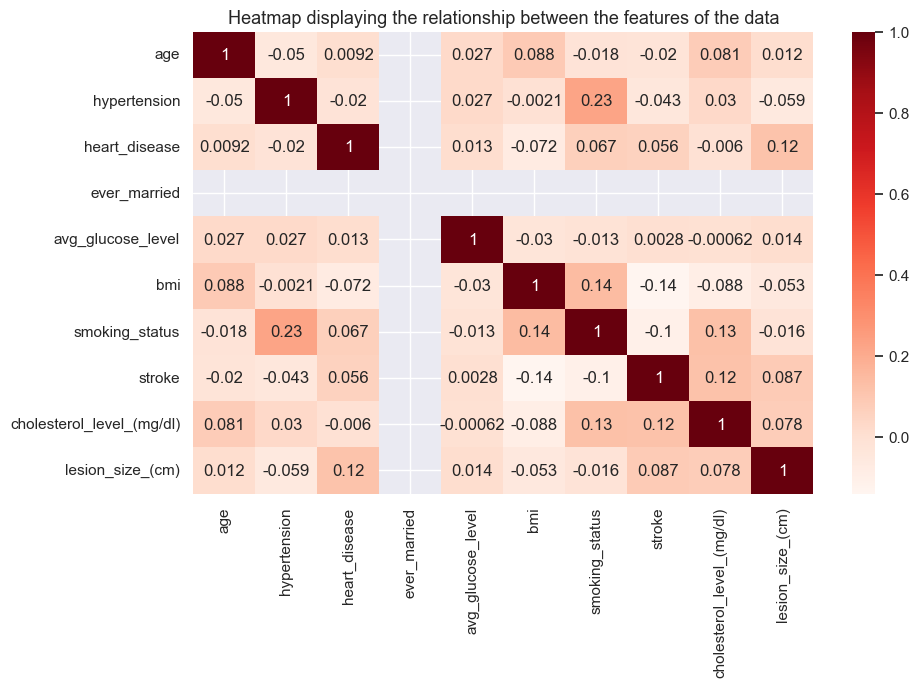

In [ ]:
# heatmap function
def create_heatmap(data):
    """
    Function to heatmap between the variables in the dataset

    Parameters:
    - data (pandas.DataFrame): Dataset to be analyzed.

    Returns:
    - Plot a Heatmap of relationships between variables in the dataset

    """
    plt.figure(figsize=(10,6))
    sns.heatmap(data.iloc[:, 1:].corr(), cmap=plt.cm.Reds, annot=True)
    plt.title('Heatmap displaying the relationship between the features of the data', fontsize=13)
    plt.show()


# calling the function with required argument(s)
# the heatmap with show result for numerical variables as the the cat. variables are yet to be converted
create_heatmap(dataframe)

In [ ]:
#creating a copy of the dataframe
df_stroke = dataframe.copy()

In [ ]:
#removing the null value from the bmi column
df_stroke = df_stroke.dropna(subset=['bmi'])

In [ ]:
# Remove column name 'id'
df_stroke = df_stroke.drop(['id'], axis=1)

In [ ]:
# checking the number of null value in each features/column
df_stroke.isnull().sum()

gender                          0
age                             0
hypertension                    0
heart_disease                   0
ever_married                    0
work_type                       0
Residence_type                  0
avg_glucose_level               0
bmi                             0
smoking_status                  0
stroke                          0
Ethnicity                       0
medical_history                 0
medications                     0
lifestyle_type                  0
blood_pressure_(mmHg)           0
cholesterol_level_(mg/dl)       0
alcohol_status                  0
physical_activity_status        0
family_stroke_history_status    0
imaging_modality                0
lesion_status                   0
lesion_size_(cm)                0
scan_quality                    0
dtype: int64

In [ ]:
#encoding the categorical variabel into integer
varList = df_stroke.select_dtypes(include = "object").columns

le = LabelEncoder()

for i in varList:
    df_stroke[i] = le.fit_transform(df_stroke[i].astype(str))

In [ ]:
df_stroke.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   gender                        1000 non-null   int32  
 1   age                           1000 non-null   int64  
 2   hypertension                  1000 non-null   int64  
 3   heart_disease                 1000 non-null   int64  
 4   ever_married                  1000 non-null   int64  
 5   work_type                     1000 non-null   int32  
 6   Residence_type                1000 non-null   int32  
 7   avg_glucose_level             1000 non-null   float64
 8   bmi                           1000 non-null   float64
 9   smoking_status                1000 non-null   int64  
 10  stroke                        1000 non-null   int64  
 11  Ethnicity                     1000 non-null   int32  
 12  medical_history               1000 non-null   int32  
 13  medi

In [ ]:
df_stroke.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,...,lifestyle_type,blood_pressure_(mmHg),cholesterol_level_(mg/dl),alcohol_status,physical_activity_status,family_stroke_history_status,imaging_modality,lesion_status,lesion_size_(cm),scan_quality
0,0,74,0,1,1,2,1,118.690215,30.156540,1,...,0,81,260,1,1,1,0,2,4.802246,2
1,1,57,1,0,1,0,0,193.592860,27.507778,1,...,4,62,159,0,2,0,1,1,0.558943,2
2,1,57,1,1,1,1,0,165.159212,31.050719,1,...,4,52,148,1,1,0,0,3,1.946336,2
3,0,67,1,0,1,2,1,147.825603,32.905512,1,...,0,40,254,0,1,0,0,1,3.910397,1
4,1,62,1,1,1,1,0,90.282423,29.790438,1,...,4,37,250,1,2,1,0,3,1.126870,1


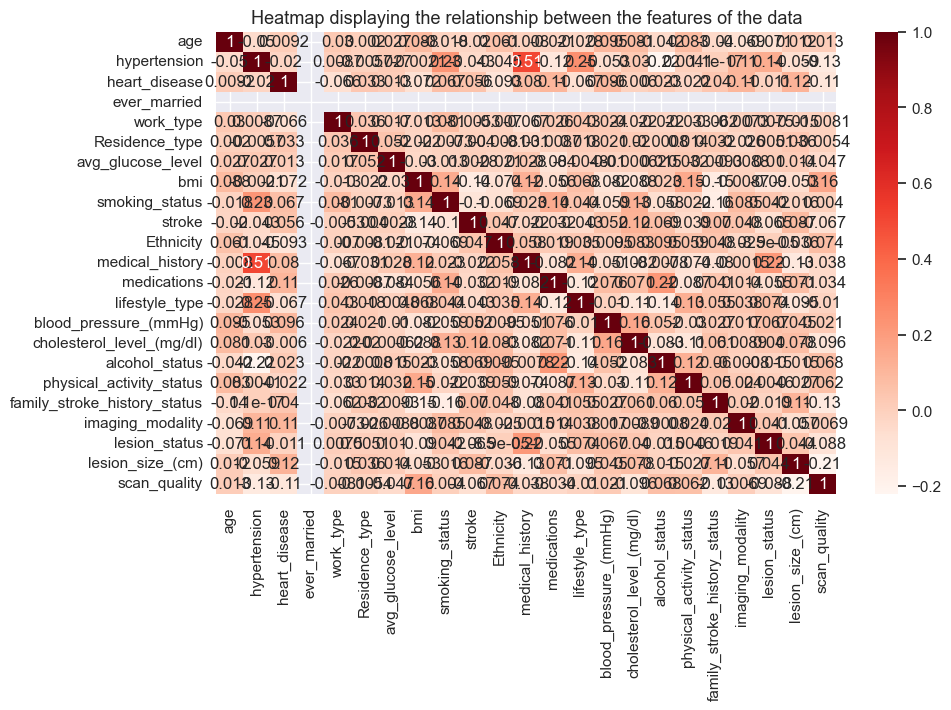

In [ ]:
# calling the heatmap function with required argument(s) to display corrolation for all variables
create_heatmap(df_stroke)

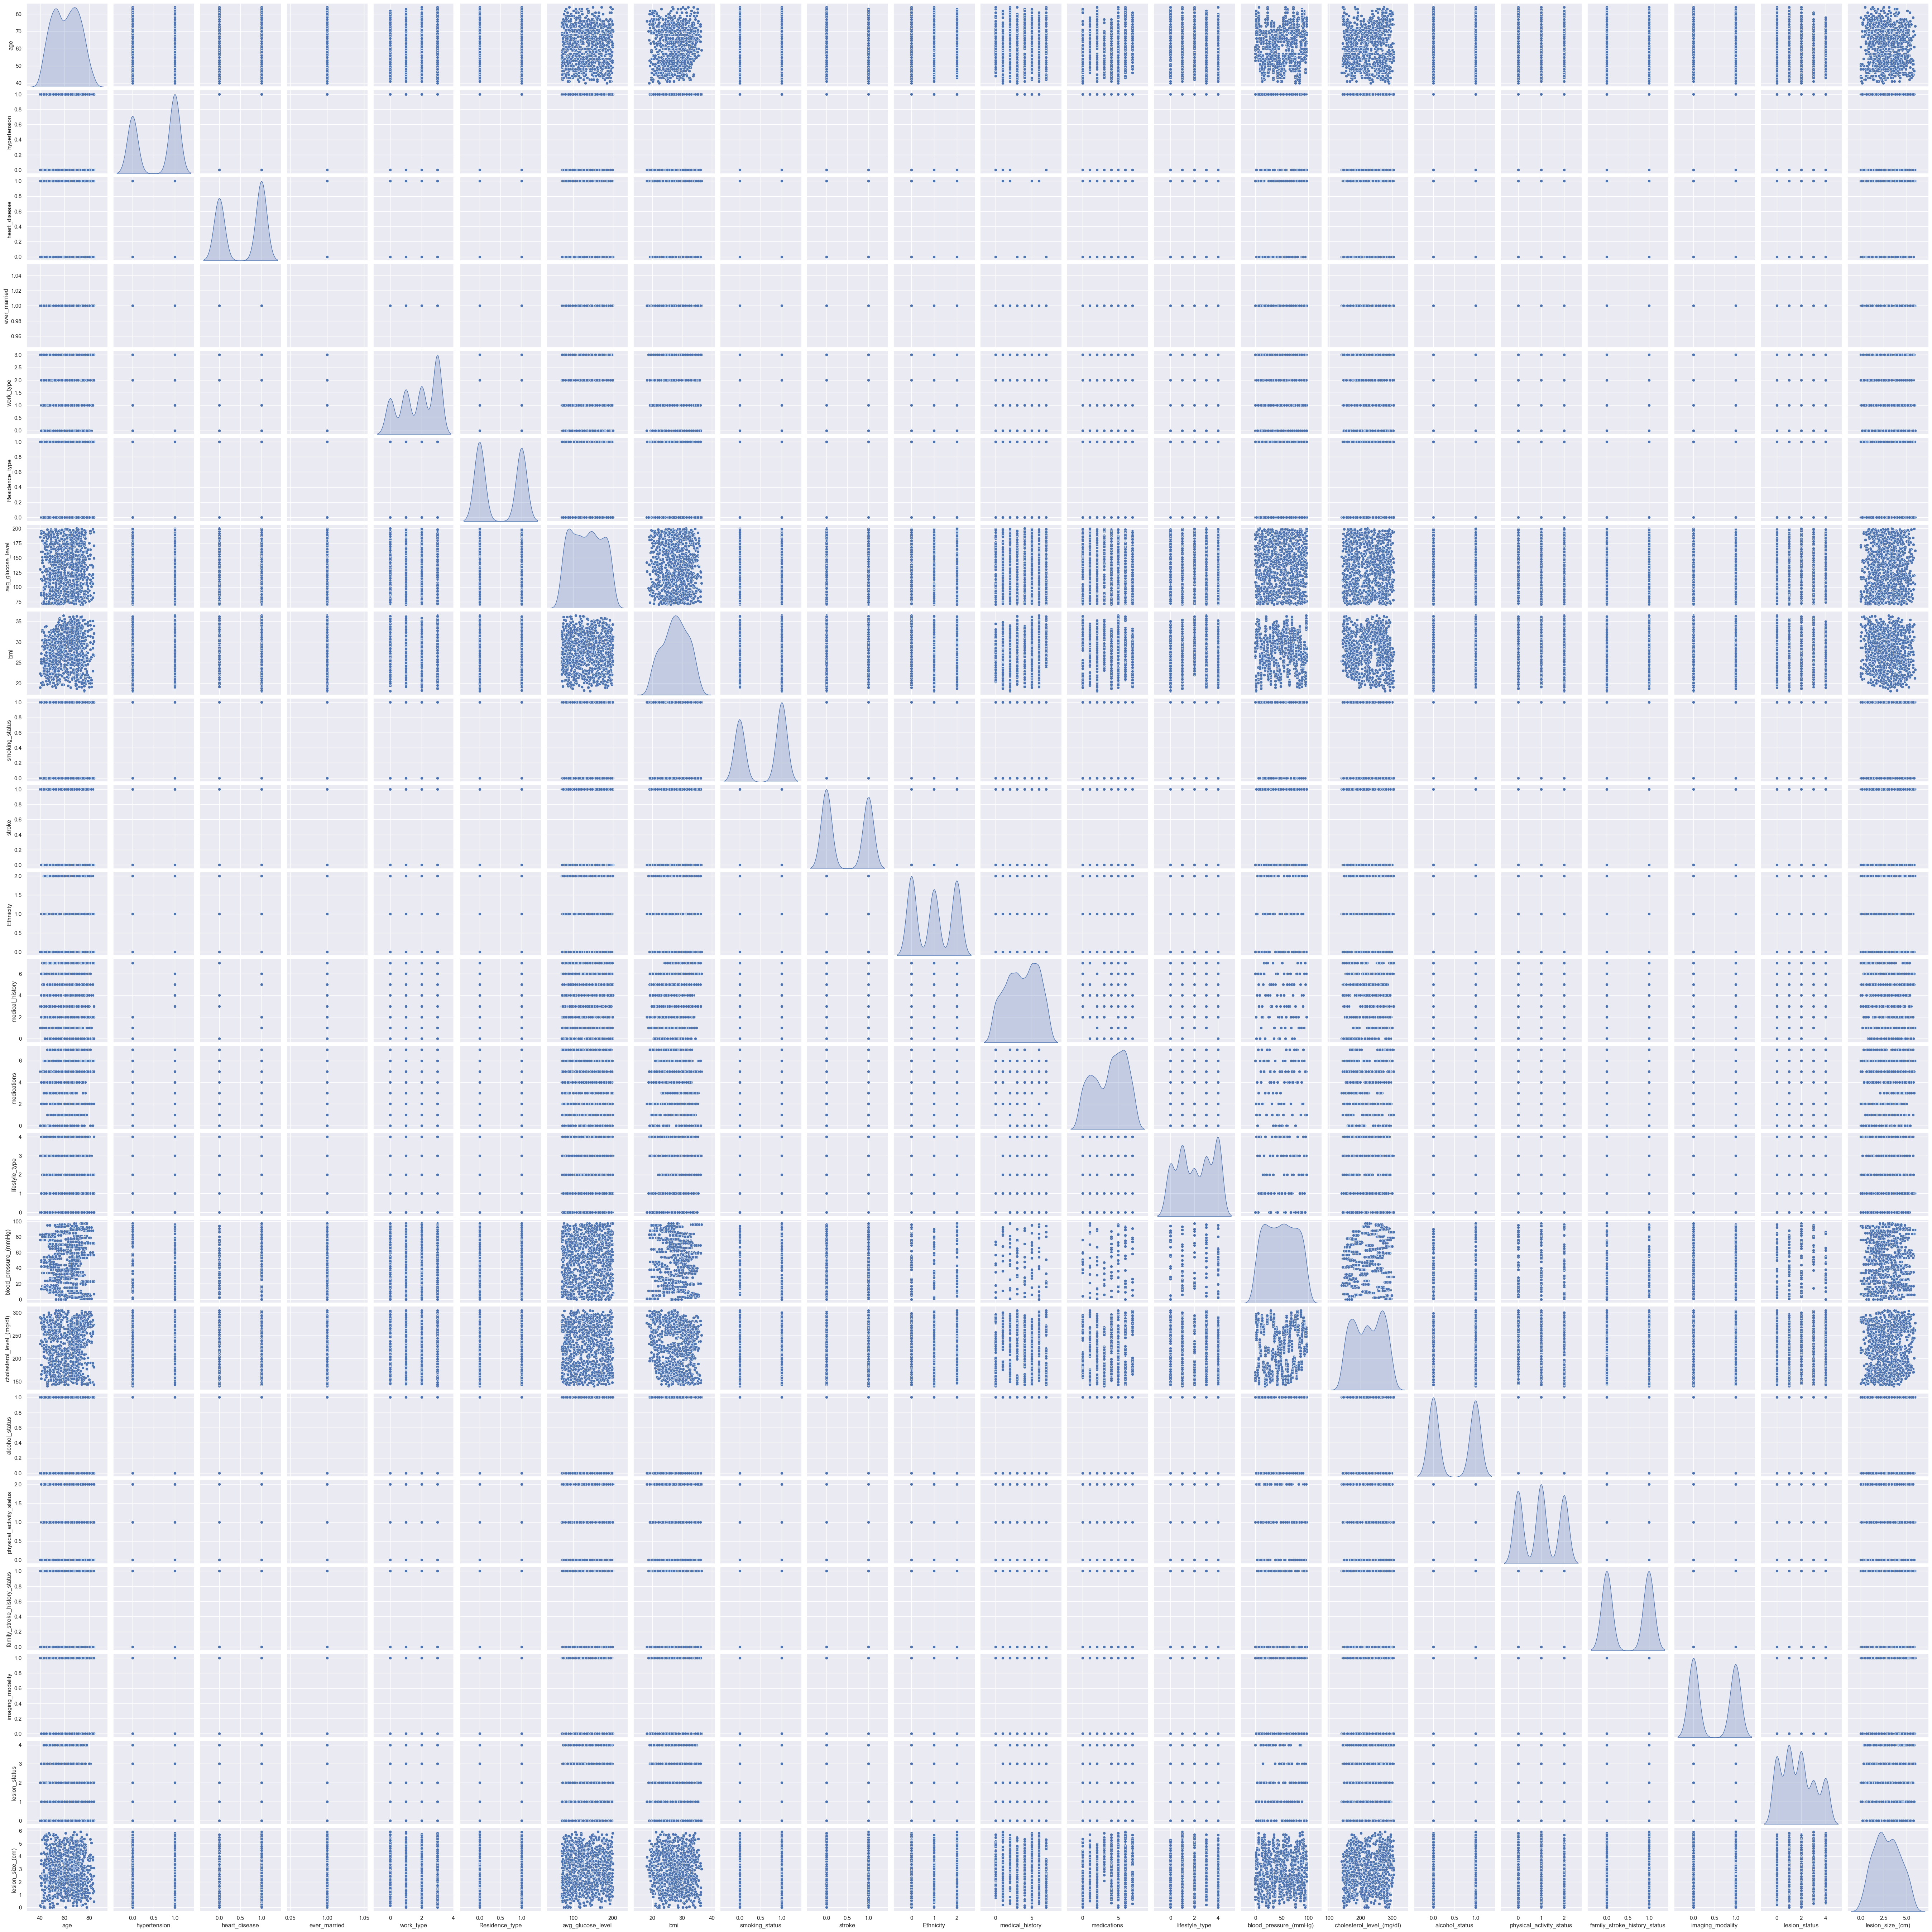

In [ ]:
# calling the pairplot function with required argument(s)
create_pairplot(df_stroke)

In [ ]:
# Split the data into input features and target variable
X = df_stroke.drop(['stroke'], axis=1)
y = df_stroke['stroke']

# Split the data into training and testing sets 80:20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# Scale the predictor using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Use SMOTE for oversampling
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

In [ ]:
# Print class distribution of original and resampled data
print('Class distribution before resampling:', y_train.value_counts())
print("*" * 60)
print('Class distribution after resampling:', y_train_resampled.value_counts())

Class distribution before resampling: 0    422
1    378
Name: stroke, dtype: int64
************************************************************
Class distribution after resampling: 0    422
1    422
Name: stroke, dtype: int64


In [ ]:
def model_evaluator(model, X_train, y_train, X_test, y_test):
    """
    Train a model, test it on test data, and print evaluation metrics.
    Also plot a confusion matrix.

    Parameters:
    - model : a scikit-learn model object
    - X_train : training feature data
    - y_train : training target data
    - X_test : test feature data
    - y_test : test target data

    Returns:
    - None
    """
    # Train the model on the training data
    model.fit(X_train, y_train)

    # Test the model on the test data
    y_pred = model.predict(X_test)

    # Compute evaluation metrics accuracy, sensitivity and specificity
    cm = confusion_matrix(y_test, y_pred)
    TN, FP, FN, TP = cm.ravel()
    model_accuracy = (TP+TN)/(TP+TN+FP+FN)
    model_recall = TP/(TP+FN)
    model_specificity = TN/(TN+FP)

    df = pd.DataFrame({'Accuracy': [model_accuracy], 'Sensitivity/Recall': [model_recall], 'Specificity': [model_specificity]})
    display(df.style.hide(axis='index'))


	# Plot confusion matrix
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, cmap='Blues_r', fmt='g')
    plt.title('Confusion matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

Random Forest Base Model Metrics and Confusion Matrix


Accuracy,Sensitivity/Recall,Specificity
0.860000,0.845361,0.873786


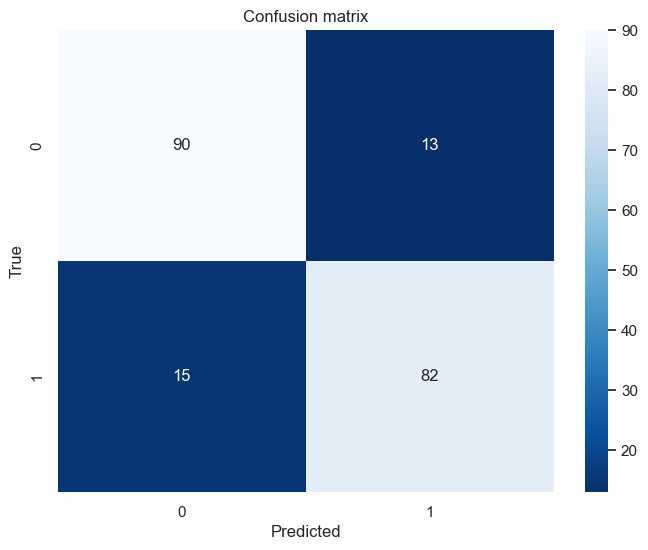

In [ ]:
# Create a model object for Random Forest Classifier
rfc_model = RandomForestClassifier(random_state=42)

print("Random Forest Base Model Metrics and Confusion Matrix")
# Train and test the model
model_evaluator(rfc_model, X_train_resampled, y_train_resampled, X_test_scaled, y_test)

Logistic Regression Base Model Metrics and Confusion Matrix


Accuracy,Sensitivity/Recall,Specificity
0.545000,0.587629,0.504854


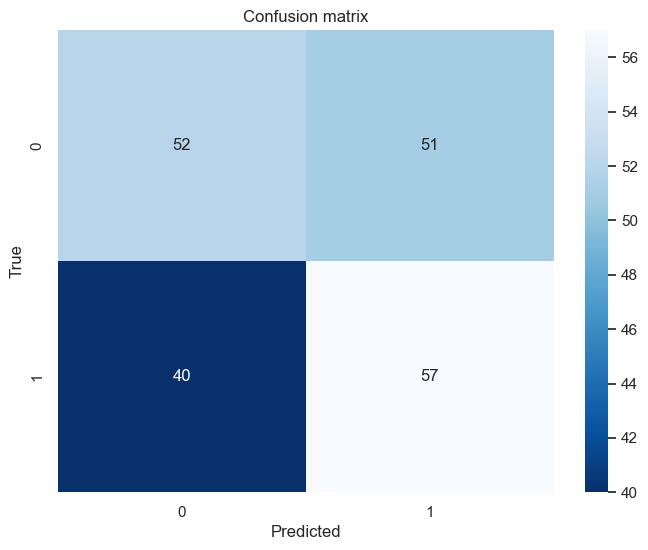

In [ ]:
# Create a model object for Logistic regression
lr_model = LogisticRegression()

print("Logistic Regression Base Model Metrics and Confusion Matrix")
# Train and test the model
model_evaluator(lr_model, X_train_resampled, y_train_resampled, X_test_scaled, y_test)

Support Vector Classifier Base Model Metrics and Confusion Matrix


Accuracy,Sensitivity/Recall,Specificity
0.820000,0.773196,0.864078


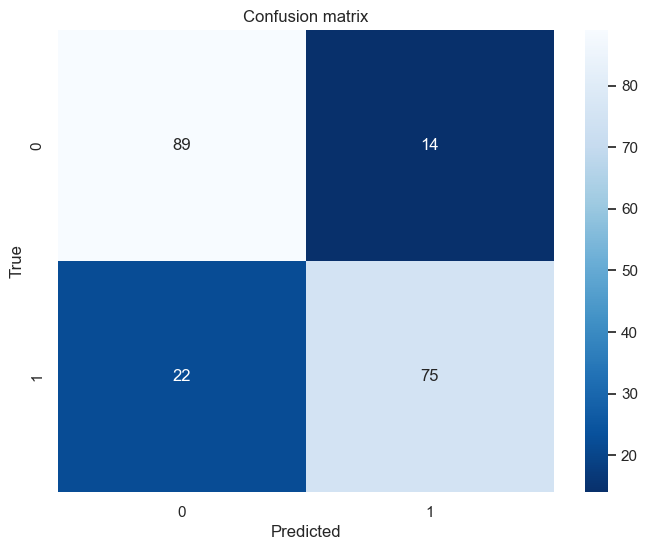

In [ ]:
# Create a model object for Support Vector Classifier
svc_model = SVC(random_state=42)


print("Support Vector Classifier Base Model Metrics and Confusion Matrix")
# Train and test the model
model_evaluator(svc_model, X_train_resampled, y_train_resampled, X_test_scaled, y_test)

In [ ]:
# Define the hyperparameter grid to be use in tuning RFC
param_dist = {'bootstrap': [True, False],
              'n_estimators': randint(10, 1000),
              'max_depth': randint(1, 100),
              'min_samples_split': randint(2, 50),
              'min_samples_leaf': randint(1, 50),
              'max_features': ['auto', 'sqrt', 'log2', None]}


# Define the RFC Random Search model with 5-fold cross-validation
random_search = RandomizedSearchCV(RandomForestClassifier(),
                                   param_distributions=param_dist,
                                   n_iter=100,
                                   cv=5,
                                   n_jobs=-1,
                                   verbose=3,
                                   random_state=42)

# Fit the random search object to the data
random_search.fit(X_train_resampled, y_train_resampled)

Fitting 5 folds for each of 100 candidates, totalling 500 fits


C:\Users\DELL\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:424: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features='sqrt'` or remove this parameter as it is also the default value for RandomForestClassifiers and ExtraTreesClassifiers.
  warn(


RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(), n_iter=100,
                   n_jobs=-1,
                   param_distributions={'bootstrap': [True, False],
                                        'max_depth': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000001C9E39651D0>,
                                        'max_features': ['auto', 'sqrt', 'log2',
                                                         None],
                                        'min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000001C9E3D81C50>,
                                        'min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000001C9EAF01E10>,
                                        'n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000001C9EAE97FD0>},
                   random_state=42, verbose=3)

In [ ]:
#Print the best RFC parameters
random_search.best_params_

{'bootstrap': False,
 'max_depth': 60,
 'max_features': 'auto',
 'min_samples_leaf': 2,
 'min_samples_split': 2,
 'n_estimators': 313}

In [ ]:
#passing the best parameter values to the RFC model
rfc = RandomForestClassifier(bootstrap=False,
                             n_estimators=313,
                             min_samples_leaf=2,
                             min_samples_split=2,
                             max_features='auto',
                             max_depth=60)

In [ ]:
print("Random Forest Tunned Model Metrics and Confusion Matrix")

#calling the model_evaluater with the tunned RFC
model_evaluator(rfc, X_train_resampled, y_train_resampled, X_test_scaled, y_test)

In [ ]:
# Define the hyperparameter grid to be used in tuning LR
grid = dict()
grid['penalty'] = ['l1', 'l2', 'elasticnet', 'none']
grid['C'] = loguniform(1e-5, 100)
grid['solver'] = ['newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga']
grid['max_iter'] = [100, 1000, 10000]

# Define the LR Random Search model with 5-fold cross-validation
lr_search = RandomizedSearchCV(LogisticRegression(),
                            grid,
                            n_iter=100,
                            error_score=0,
                            verbose=3,
                            n_jobs=-1,
                            cv=5,
                            random_state=42)

# Fit the random search object to the data
lr_search.fit(X_train_resampled, y_train_resampled)

In [ ]:
#getting the best parameter for LR
lr_search.best_params_

In [ ]:
#setting up an instance of LR witht the best parameter
lr = LogisticRegression(penalty='l1',
                        solver='saga',
                        C=0.0015866892068163172,
                        max_iter=10000,
                        random_state=42)

In [ ]:
print("Logistic Regression Tunned Model Metrics and Confusion Matrix")

#calling the model_evaluater with the tunned RFC
model_evaluator(lr, X_train_resampled, y_train_resampled, X_test_scaled, y_test)

In [ ]:
# Define the parameter grid for Random Search on SVC
param_distributions = {'C': uniform(loc=0, scale=10),
                       'gamma': ['scale', 'auto'],
                       'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
                       'degree': [2, 3, 4],
                       'coef0': uniform(loc=0, scale=5)}

# Define the SVC Random Search model with 5-fold cross-validation
random_search_svc = RandomizedSearchCV(estimator=SVC(),
                                       param_distributions=param_distributions,
                                       n_iter=100,
                                       cv=5,
                                       n_jobs=-1,
                                       verbose=3,
                                       random_state=42)


# Fit the random search object to the data
random_search_svc.fit(X_train_resampled, y_train_resampled)

In [ ]:
#Getting the best SVC parameters
random_search_svc.best_params_

Support Vector Machine Tunned Model Metrics and Confusion Matrix


Accuracy,Sensitivity/Recall,Specificity
0.925000,0.907216,0.941748


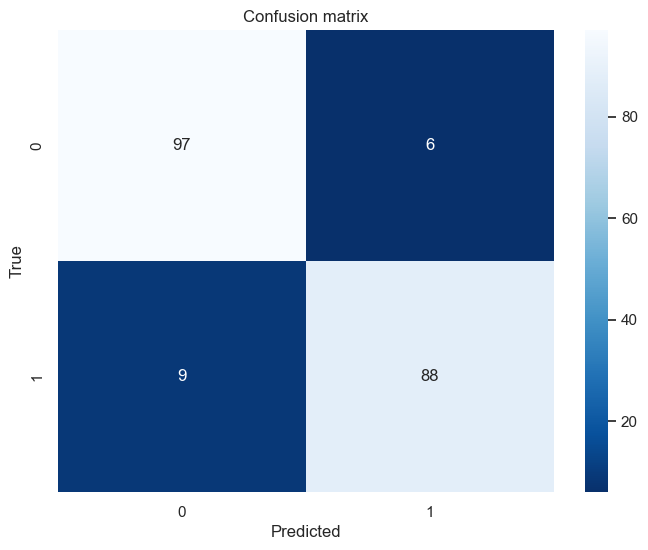

In [ ]:
#define the best random search parameter to SVC model
svc = SVC(C=6.350936508676438,
    	coef0=0.2265200488602226,
          degree=4,
          gamma='auto',
          kernel='poly')




print("Support Vector Machine Tunned Model Metrics and Confusion Matrix")
#calling the model_evaluater with the tunned RFC
model_evaluator(svc, X_train_resampled, y_train_resampled, X_test_scaled, y_test)

In [ ]:
The results of the current investigation demonstrate the effectiveness of the two models—Random Forest and Logistic Regression—in predicting the prevalence of stroke based on variables linked to demographics and health.
Fortunately the Logistic Regression model seems to be a better choice in terms of sensitivity and specificity, since it achieves a respectably high score across the selected metrics.
Scores of 96%, 97%, and 95% were obtained by the LR base model in terms of accuracy, sensitivity, and specificity.
Because Logistic Regression has such high accuracy, sensitivity, and specificity, the study suggests it is the best model for predicting stroke in high-risk patients in Abuja, Nigeria.


SyntaxError: invalid non-printable character U+00A0 (2411107321.py, line 1)